In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import schemdraw
import schemdraw.elements as elm
from IPython.display import Audio, display, HTML

%config InlineBackend.figure_format = 'svg'
FS = 44100

def jouer_son(titre, sig, volume=0.35):
    sig_norm = sig / (np.max(np.abs(sig)) + 1e-9) * volume
    display(HTML(f"<b>🔊 {titre}</b>"))
    display(Audio(sig_norm, rate=FS))


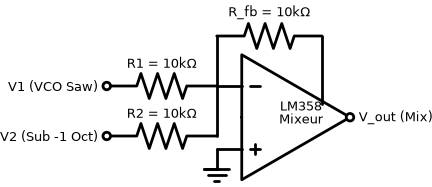

In [4]:
# Formule : V_out = - R_fb * (V1/R1 + V2/R2)
# Si R1 = R2 = R_fb = 10 kOhm -> Chaque voie a un gain de -1 (mixage équilibré)
R1, R2, R_fb = 10000.0, 10000.0, 10000.0

with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)
    op = elm.Opamp().label("LM358\nMixeur", loc="center")
    d += op

    # Entrée 1 (VCO Saw)
    d += elm.Line().left(0.5).at(op.in1)
    d.push()
    d += elm.Resistor().left().label("R1 = 10kΩ")
    d += elm.Dot(open=True).label("V1 (VCO Saw)", loc="left")
    d.pop()

    # Entrée 2 (Sub-Oscillateur)
    d.push()
    d += elm.Line().down(1.0)
    d += elm.Resistor().left().label("R2 = 10kΩ")
    d += elm.Dot(open=True).label("V2 (Sub -1 Oct)", loc="left")
    d.pop()

    # Contre-réaction (Gain)
    d += elm.Line().up(1.0)
    d += elm.Resistor().right(2.1).label("R_fb = 10kΩ")
    d += elm.Line().down(1.35)

    # Masse sur entrée + (ou V_ref = Vcc/2 en alimentation simple)
    d += elm.Line().left(0.5).at(op.in2)
    d += elm.Ground()

    d += elm.Dot(open=True).at(op.out).label("V_out (Mix)", loc="right")

# Écoute du mélange Saw (110 Hz) + Sub Carré (55 Hz)
t = np.linspace(0, 1.5, int(FS * 1.5), endpoint=False)
vco_saw = signal.sawtooth(2 * np.pi * 110.0 * t)
sub_sq = signal.square(2 * np.pi * 55.0 * t)
mix_out = -(R_fb/R1 * vco_saw + R_fb/R2 * sub_sq)

jouer_son("Mixage VCO Saw (110 Hz) + Sub-Oscillateur (55 Hz)", mix_out)


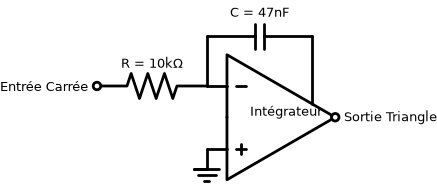

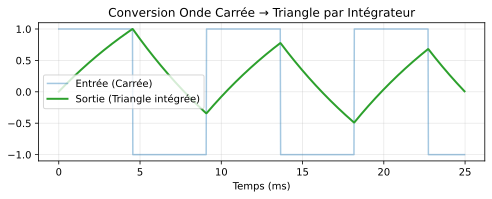

In [5]:
R_int = 10000.0   # 10 kOhm
C_int = 47e-9     # 47 nF

with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)
    op = elm.Opamp().label("Intégrateur", loc="center")
    d += op
    d += elm.Line().left(0.4).at(op.in1)
    d.push()
    d += elm.Resistor().left().label("R = 10kΩ")
    d += elm.Dot(open=True).label("Entrée Carrée", loc="left")
    d.pop()
    d += elm.Line().up(1.0)
    d += elm.Capacitor().right(2.1).label("C = 47nF")
    d += elm.Line().down(1.35)
    d += elm.Line().left(0.4).at(op.in2)
    d += elm.Ground()
    d += elm.Dot(open=True).at(op.out).label("Sortie Triangle", loc="right")

# Simulation visuelle et sonore
t_int = np.linspace(0, 1.2, int(FS * 1.2), endpoint=False)
carre = signal.square(2 * np.pi * 110.0 * t_int)
# Intégration passe-bas (avec légère fuite DC)
b_i, a_i = signal.butter(1, 15.0 / (FS / 2), btype='low')
triangle = signal.lfilter(b_i, a_i, carre)

zoom = int(0.025 * FS)
plt.figure(figsize=(8, 2.5))
plt.plot(t_int[:zoom]*1000, carre[:zoom], alpha=0.4, label="Entrée (Carrée)")
plt.plot(t_int[:zoom]*1000, triangle[:zoom] / np.max(np.abs(triangle)), linewidth=2, color="#2ca02c", label="Sortie (Triangle intégrée)")
plt.title("Conversion Onde Carrée → Triangle par Intégrateur")
plt.xlabel("Temps (ms)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

jouer_son("Onde Triangle obtenue après intégration", triangle)


🎛️ Fréquence de coupure Sallen-Key : fc = 482.3 Hz


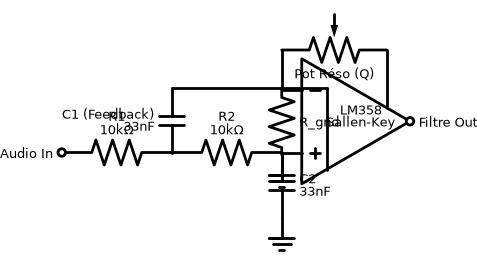

/tmp/ipykernel_12979/2118939853.py:52: RuntimeWarning: overflow encountered in scalar multiply
  fb = Q * (z1 - z2)
/tmp/ipykernel_12979/2118939853.py:52: RuntimeWarning: invalid value encountered in scalar subtract
  fb = Q * (z1 - z2)


/home/dev/projects/digital-analog-synthetizeur/hardware/.venv/lib/python3.14/site-packages/IPython/lib/display.py:187: RuntimeWarning: invalid value encountered in cast
  return scaled.astype("<h").tobytes(), nchan


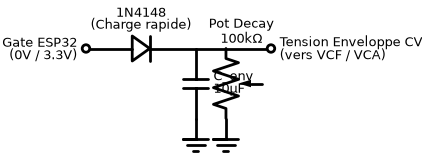

In [6]:
# Formule Sallen-Key (avec R1 = R2 = R et C1 = C2 = C) :
# fc = 1 / (2 * pi * R * C)
# Résonance Q = 1 / (3 - Gain_Ampli)   (Attention : si Gain >= 3, le filtre auto-oscille !)

R_sk = 10000.0    # 10 kOhm
C_sk = 33e-9      # 33 nF
fc_sk = 1 / (2 * np.pi * R_sk * C_sk)
print(f"🎛️ Fréquence de coupure Sallen-Key : fc = {fc_sk:.1f} Hz")

with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)
    op = elm.Opamp().label("LM358\nSallen-Key", loc="center")
    d += op

    # Branche d'entrée R1 -> R2 -> Entrée +
    d += elm.Line().left(0.4).at(op.in2)
    d.push()
    d += elm.Capacitor().down(1.3).label("C2\n33nF", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += (r2 := elm.Resistor().left().label("R2\n10kΩ"))
    d.push()
    d += elm.Capacitor().up(1.3).label("C1 (Feedback)\n33nF")
    d += elm.Line().right(3.1)
    d += elm.Line().down(1.65)
    d.pop()
    d += elm.Resistor().left().label("R1\n10kΩ")
    d += elm.Dot(open=True).label("Audio In", loc="left")

    # Réglage de Résonance sur entrée -
    d += elm.Line().left(0.4).at(op.in1)
    d.push()
    d += elm.Resistor().down(1.3).label("R_gnd", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += elm.Line().up(0.8)
    d += elm.Potentiometer().right(2.1).label("Pot Réso (Q)")
    d += elm.Line().down(1.15)
    d += elm.Dot(open=True).at(op.out).label("Filtre Out", loc="right")

# Simulation d'un balayage (Sweep) de filtre Acid de 150 Hz à 2500 Hz
t_sw = np.linspace(0, 2.0, int(FS * 2.0), endpoint=False)
saw_acid = signal.sawtooth(2 * np.pi * 55.0 * t_sw)
out_sweep = np.zeros_like(saw_acid)

# Balayage logarithmique de la coupure avec forte résonance (Q = 7)
fc_env = 150.0 + 2200.0 * np.exp(-((t_sw % 0.5) / 0.12))
z1, z2 = 0.0, 0.0
Q = 7.0
for i in range(len(saw_acid)):
    f_cut = np.clip(2 * np.sin(np.pi * fc_env[i] / FS), 0.01, 0.8)
    fb = Q * (z1 - z2)
    z1 += f_cut * (saw_acid[i] - z1 + fb)
    z2 += f_cut * (z1 - z2)
    out_sweep[i] = z2

jouer_son("Balayage (Sweep) Filtre Résonant Sallen-Key (Q=7)", out_sweep)
with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)
    d += elm.Dot(open=True).label("Gate ESP32\n(0V / 3.3V)", loc="left")
    d += elm.Diode().right().label("1N4148\n(Charge rapide)")
    d.push()
    d += elm.Capacitor().down(1.4).label("C_env\n10µF", loc="bottom")
    d += elm.Ground()
    d.pop()
    d.push()
    d += elm.Potentiometer().down(1.4).at((2.8, 0)).label("Pot Decay\n100kΩ", loc="right")
    d += elm.Ground()
    d.pop()
    d += elm.Line().right(1.5)
    d += elm.Dot(open=True).label("Tension Enveloppe CV\n(vers VCF / VCA)", loc="right")

# Écoute de l'enveloppe appliquée sur une note continue
t_vca = np.linspace(0, 1.5, int(FS * 1.5), endpoint=False)
osc_continu = signal.sawtooth(2 * np.pi * 65.41 * t_vca)
# 3 déclenchements Gate espacés de 0.5s
enveloppe_vca = np.exp(-((t_vca % 0.5) / 0.10))
son_sculpte = osc_continu * enveloppe_vca

jouer_son("Oscillateur continu sculpté par l'enveloppe Decay (VCA)", son_sculpte)


🔋 Alimentation simple 5.0V -> Masse virtuelle V_ref = 2.50V


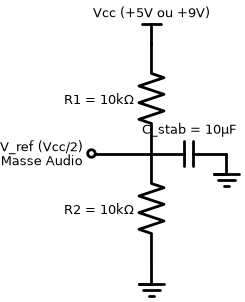

In [7]:
vcc = 5.0
v_ref = vcc / 2.0
print(f"🔋 Alimentation simple {vcc}V -> Masse virtuelle V_ref = {v_ref:.2f}V")

with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)
    d += elm.Vdd().label("Vcc (+5V ou +9V)")
    d += elm.Resistor().down().label("R1 = 10kΩ")
    d.push()
    d += elm.Capacitor().right(1.5).label("C_stab = 10µF")
    d += elm.Ground()
    d.pop()
    d.push()
    d += elm.Line().left(1.2)
    d += elm.Dot(open=True).label("V_ref (Vcc/2)\nMasse Audio", loc="left")
    d.pop()
    d += elm.Resistor().down().label("R2 = 10kΩ")
    d += elm.Ground()


🔋 Alimentation simple 5.0V -> Masse virtuelle V_ref = 2.50V


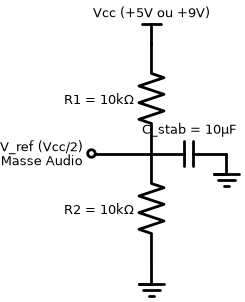

In [8]:
vcc = 5.0
v_ref = vcc / 2.0
print(f"🔋 Alimentation simple {vcc}V -> Masse virtuelle V_ref = {v_ref:.2f}V")

with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)
    d += elm.Vdd().label("Vcc (+5V ou +9V)")
    d += elm.Resistor().down().label("R1 = 10kΩ")
    d.push()
    d += elm.Capacitor().right(1.5).label("C_stab = 10µF")
    d += elm.Ground()
    d.pop()
    d.push()
    d += elm.Line().left(1.2)
    d += elm.Dot(open=True).label("V_ref (Vcc/2)\nMasse Audio", loc="left")
    d.pop()
    d += elm.Resistor().down().label("R2 = 10kΩ")
    d += elm.Ground()
